# 第 9 章 蒙特卡罗积分与方差缩减 — 代码实验

对照教材：Dunn & Shultis《Exploring Monte Carlo Methods》Ch.5；Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》§6.3.1。

每个实验都报"估计值 ± 标准误差"，并与模拟方差缩减比对照——方差缩减的成败只看一件事：**同样 \(N\) 条 history，标准差小了多少**。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch09")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2024)
print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 重要性抽样：∫₀¹ e^{7x}dx（D&S §5.2 / 习题 1）

朴素抽样在 [0,1] 均匀取点，被积函数在右端翘得很高，绝大多数样本贡献很小。取 \(f^*(x)\propto 3^{7x}\) 作重要性函数，权重 \(W=f/f^*\)。

In [2]:
exact1 = (np.exp(7.0) - 1) / 7.0          # ∫₀¹ e^{7x} dx
N = 200_000

x = rng.random(N)                          # 朴素
z_plain = np.exp(7 * x)
est_plain, se_plain = z_plain.mean(), z_plain.std(ddof=1) / np.sqrt(N)

# f* ∝ 3^{7x} = e^{7x ln3}
a = 7 * np.log(3.0)
norm = (np.exp(a) - 1) / a                  # 归一化常数
u = rng.random(N)
xs = np.log(1 + u * (np.exp(a) - 1)) / a    # 逆 CDF 抽样
fs = np.exp(a * xs) / norm
W = 1.0 / fs                                # f = 1 on [0,1]
z_is = np.exp(7 * xs) * W
est_is, se_is = z_is.mean(), z_is.std(ddof=1) / np.sqrt(N)

print(f"精确值        = {exact1:.4f}")
print(f"朴素抽样      = {est_plain:.4f} ± {se_plain:.4f}")
print(f"重要性抽样    = {est_is:.4f} ± {se_is:.4f}")
print(f"标准差比（朴素/重要性） = {se_plain/se_is:.1f} 倍")

精确值        = 156.5190
朴素抽样      = 155.3677 ± 0.5516
重要性抽样    = 156.5242 ± 0.0337
标准差比（朴素/重要性） = 16.4 倍


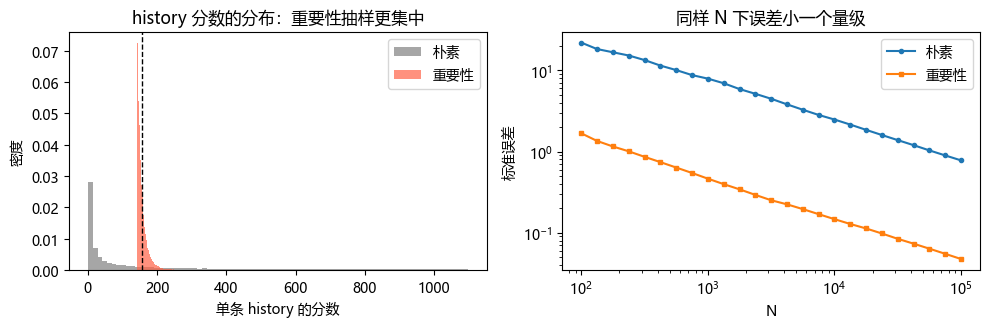

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(z_plain, bins=80, density=True, color="gray", alpha=0.7, label="朴素")
ax[0].hist(z_is, bins=80, density=True, color="tomato", alpha=0.7, label="重要性")
ax[0].axvline(exact1, color="k", ls="--", lw=1)
ax[0].set_xlabel("单条 history 的分数"); ax[0].set_ylabel("密度")
ax[0].legend(); ax[0].set_title("history 分数的分布：重要性抽样更集中")

Ns = np.unique(np.logspace(2, 5, 25).astype(int))
def se_run(vals, n):
    return vals[:n].std(ddof=1) / np.sqrt(n)
ax[1].loglog(Ns, [se_run(z_plain, n) for n in Ns], "o-", ms=3, label="朴素")
ax[1].loglog(Ns, [se_run(z_is, n) for n in Ns], "s-", ms=3, label="重要性")
ax[1].set_xlabel("N"); ax[1].set_ylabel("标准误差"); ax[1].legend()
ax[1].set_title("同样 N 下误差小一个量级")
fig.tight_layout(); save(fig, "out-9-1.png"); plt.show()

## 实验 2 理论上最优的 f* 给出零方差（D&S 式 5.9–5.10）

取 \(f^*(x)=|g(x)|/\int|g|\)，则 \(g/f^*\) 恒为常数，方差为零。用 \(g(x)=3x^2\)（\(x\in[0,1]\)，积分 1）验证：\(f^*(x)=3x^2\)，\(g/f^*\equiv 1\)。

In [4]:
N = 100_000
u = rng.random(N)
xs = u ** (1/3)                     # 从 f*(x)=3x² 抽样（逆 CDF: x=u^{1/3}）
ratio = (3 * xs**2) / (3 * xs**2)   # g/f* 恒等于 1
print(f"每条 history 的分数恒为 {ratio.min():.1f} … {ratio.max():.1f}，样本标准差 = {ratio.std(ddof=1):.2e}")
print(f"估计值 = {ratio.mean():.6f}（精确 1）")

每条 history 的分数恒为 1.0 … 1.0，样本标准差 = 0.00e+00
估计值 = 1.000000（精确 1）


## 实验 3 系统抽样：方差分解的实证（D&S §5.3.1）

取 \(g(x)=\sin(\pi x)\) 在 [0,1] 上（区域均值彼此不同）。把 [0,1] 均分成 \(M\) 段，每段按 \(N_m=p_mN\) 抽样。理论：朴素方差 \(=\frac1N\sum p_m\sigma_m^2+\frac1N\sum p_m(\bar z_m-\bar z)^2\)，系统抽样方差只剩第一项。

In [5]:
def systematic_estimate(M, N, rng):
    # 各层按 p_m = 1/M 分配 N_m，层内均匀抽样；返回加权和
    edges = np.linspace(0, 1, M + 1)
    est = 0.0
    for m in range(M):
        Nm = N // M + (1 if m < N % M else 0)
        xm = rng.uniform(edges[m], edges[m+1], Nm)
        est += (1/M) * np.sin(np.pi * xm).mean()   # p_m = 1/M
    return est

M, N = 16, 160_000
# 用 200 次重复评估估计量的真实方差（比单次样本标准差可靠）
reps = 200
est_sys = np.array([systematic_estimate(M, N, rng) for _ in range(reps)])
est_sf = np.array([np.sin(np.pi*rng.random(N)).mean() for _ in range(reps)])
# 理论分解
p = 1/M
edges = np.linspace(0, 1, M+1)
means, varis = [], []
for m in range(M):
    xg = np.linspace(edges[m], edges[m+1], 4001)
    means.append(np.sin(np.pi*xg).mean()); varis.append(np.sin(np.pi*xg).var())
means, varis = np.array(means), np.array(varis)
grand = np.sin(np.pi*np.linspace(0,1,200001)).mean()
th_sys = p * varis.mean() / N
th_sf = th_sys + p * ((means-grand)**2).mean() / N
print(f"单次估计：系统 {est_sys[0]:.5f}；朴素 {est_sf[0]:.5f}")
print(f"200 次重复的实测标准误：系统 {est_sys.std(ddof=1):.2e}，朴素 {est_sf.std(ddof=1):.2e}，比 {est_sf.std(ddof=1)/est_sys.std(ddof=1):.2f}")
print(f"理论标准误：系统 {np.sqrt(th_sys):.2e}，朴素 {np.sqrt(th_sf):.2e}，比 {np.sqrt(th_sf/th_sys):.2f}")

单次估计：系统 0.63677；朴素 0.63780
200 次重复的实测标准误：系统 1.09e-04，朴素 7.90e-04，比 7.24
理论标准误：系统 2.50e-05，朴素 1.92e-04，比 7.68


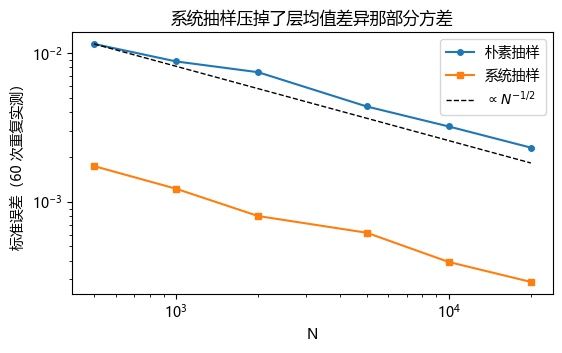

In [6]:
Ns = np.array([500, 1000, 2000, 5000, 10000, 20000])
R = 60
se_sys, se_sf = [], []
for n in Ns:
    a = np.array([systematic_estimate(M, n, rng) for _ in range(R)])
    b = np.array([np.sin(np.pi*rng.random(n)).mean() for _ in range(R)])
    se_sys.append(a.std(ddof=1)); se_sf.append(b.std(ddof=1))
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.loglog(Ns, se_sf, "o-", ms=4, label="朴素抽样")
ax.loglog(Ns, se_sys, "s-", ms=4, label="系统抽样")
ax.loglog(Ns, se_sf[0]*np.sqrt(Ns[0]/Ns), "k--", lw=1, label=r"$\propto N^{-1/2}$")
ax.set_xlabel("N"); ax.set_ylabel("标准误差（60 次重复实测）"); ax.legend()
ax.set_title("系统抽样压掉了层均值差异那部分方差")
save(fig, "out-9-2.png"); plt.show()

## 实验 4 分层抽样的最优分配（D&S §5.4，式 5.49）

三层，各层方差差别很大。平均分配 vs 按 \(N_m\propto p_m\sigma_m\) 分配，比较标准误差。

In [7]:
M = 3
p_m = np.array([1/3, 1/3, 1/3])
sig = np.array([0.1, 0.5, 2.0])       # 各层标准差（人为设定）
N = 30_000
Nopt = (p_m*sig) / (p_m*sig).sum()
N_opt = np.maximum((N*Nopt).round().astype(int), 1)
N_eq = np.full(M, N//M)
print("最优分配比例:", np.round(Nopt, 3), "→ 各层样本数", N_opt)

def stratified_var(sig, N_m):
    return np.sum(p_m**2 * sig**2 / N_m)
print(f"平均分配 方差 = {stratified_var(sig, N_eq):.3e}")
print(f"最优分配 方差 = {stratified_var(sig, N_opt):.3e}")
print(f"最小理论方差 (Σpσ)²/N = {(p_m*sig).sum()**2/N:.3e}")

最优分配比例: [0.038 0.192 0.769] → 各层样本数 [ 1154  5769 23077]
平均分配 方差 = 4.733e-05
最优分配 方差 = 2.504e-05
最小理论方差 (Σpσ)²/N = 2.504e-05


## 实验 5 对偶变量：g(x)=e^{x}（D&S §5.5.2）

用同一组 \(u_i\) 产生 \(x_i=u_i\) 与 \(y_i=1-u_i\)，取平均。对单调函数，两者强负相关。

In [8]:
N = 100_000
u = rng.random(N)
g1 = np.exp(u); g2 = np.exp(1-u)
I1 = g1.mean(); I12 = 0.5*(g1+g2).mean()
se1 = g1.std(ddof=1)/np.sqrt(N)
d = 0.5*(g1+g2)
se12 = d.std(ddof=1)/np.sqrt(N)
rho = np.corrcoef(g1, g2)[0,1]
exact = np.e - 1
print(f"精确 = {exact:.6f}")
print(f"普通   = {I1:.6f} ± {se1:.6f}")
print(f"对偶   = {I12:.6f} ± {se12:.6f}   （相关系数 ρ = {rho:.3f}）")
print(f"标准误比 = {se1/se12:.2f}（方差比 {se1**2/se12**2:.2f}）")
print(f"理论：var((I1+I2)/2)/var(I1) = (1+ρ)/2 = {(1+rho)/2:.4f}，即方差比 {2/(1+rho):.2f}")

精确 = 1.718282
普通   = 1.718231 ± 0.001557
对偶   = 1.718396 ± 0.000198   （相关系数 ρ = -0.968）
标准误比 = 7.86（方差比 61.80）
理论：var((I1+I2)/2)/var(I1) = (1+ρ)/2 = 0.0162，即方差比 61.83


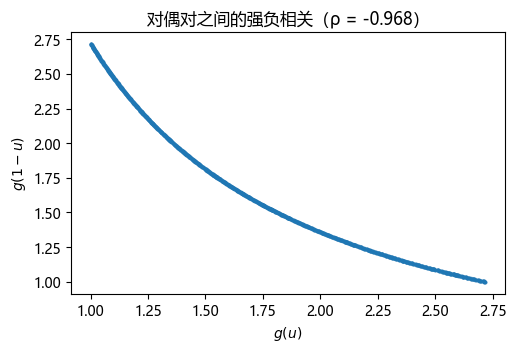

In [9]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.scatter(g1[:3000], g2[:3000], s=3, alpha=0.4)
ax.set_xlabel("$g(u)$"); ax.set_ylabel("$g(1-u)$")
ax.set_title(f"对偶对之间的强负相关（ρ = {rho:.3f}）")
save(fig, "out-9-3.png"); plt.show()

## 实验 6 控制变量：用已知积分压低方差（D&S §5.5.1）

估计 \(I=\int_0^1 e^{-x^2}dx\)。控制变量 \(z_o=g_o(x)=1-x^2\)，其期望 \(2/3\) 精确已知。最优系数 \(\alpha_{opt}=\mathrm{cov}(z,z_o)/\sigma^2(z_o)\)，最小方差比 \(1-\rho^2\)。

In [10]:
N = 200_000
x = rng.random(N)
z = np.exp(-x*x); z0 = 1 - x*x
Ez0 = 2/3
alpha = np.cov(z, z0)[0,1] / z0.var(ddof=1)
zc = z - alpha*(z0 - Ez0)
print(f"alpha_opt = {alpha:.4f}")
print(f"普通    = {z.mean():.6f} ± {z.std(ddof=1)/np.sqrt(N):.6f}")
print(f"控制变量 = {zc.mean():.6f} ± {zc.std(ddof=1)/np.sqrt(N):.6f}")
rho = np.corrcoef(z, z0)[0,1]
print(f"ρ = {rho:.4f}，理论方差比 1/(1-ρ²) = {1/(1-rho**2):.1f}，实测 {z.var(ddof=1)/zc.var(ddof=1):.1f}")
print(f"精确值 = {0.7468241328124271:.6f}")

alpha_opt = 0.6693
普通    = 0.747326 ± 0.000449
控制变量 = 0.746829 ± 0.000055
ρ = 0.9924，理论方差比 1/(1-ρ²) = 66.2，实测 66.2
精确值 = 0.746824


## 实验 7 Russian roulette 与 splitting 的无偏性（D&S §5.8）

稀有事：每条 history 以 2% 概率得分 1（朴素要 50 倍样本才有包）。用"轮盘赌"把低分 history 以概率 \(q\) 杀掉、幸存者权重除以 \(1-q\)；把"有希望"的 history 分裂成 \(m\) 份、每份权重 \(W/m\)。检验期望不变。

In [11]:
M = 400_000
score = (rng.random(M) < 0.02).astype(float)
print(f"朴素：{score.mean():.4f} ± {score.std(ddof=1)/np.sqrt(M):.5f}（真值 0.02）")

# 轮盘赌：q=0.9 杀死，幸存者权重 ×10
q = 0.9
alive = rng.random(M) > q
w_rr = np.where(alive, score / (1-q), 0.0)
print(f"轮盘赌：{w_rr.mean():.4f} ± {w_rr.std(ddof=1)/np.sqrt(M):.5f}（期望仍为 0.02，方差更大）")

# 分裂：一条 weight=1 的 history 分裂成 m=4 份，每份 weight=1/4；
# 记分要把 4 份 clone 的权重加起来（= 原权重），平均仍按"源 history 数"算。
m = 4
clones = np.repeat(score / m, m).reshape(-1, m)
tally = clones.sum(axis=1)          # 每条源 history 的总记分
print(f"分裂 m=4：{tally.mean():.4f} ± {tally.std(ddof=1)/np.sqrt(len(tally)):.5f}（等于朴素，记分守恒）")

朴素：0.0198 ± 0.00022（真值 0.02）
轮盘赌：0.0186 ± 0.00068（期望仍为 0.02，方差更大）
分裂 m=4：0.0198 ± 0.00022（等于朴素，记分守恒）


## 实验 8 加权蒙特卡罗：把收敛从 N^{-1/2} 提到 N^{-1}（D&S §5.11.1）

把样本点排序后做梯形积分。对照朴素样本均值法：前者误差 ∝ \(N^{-1}\)，后者 ∝ \(N^{-1/2}\)。

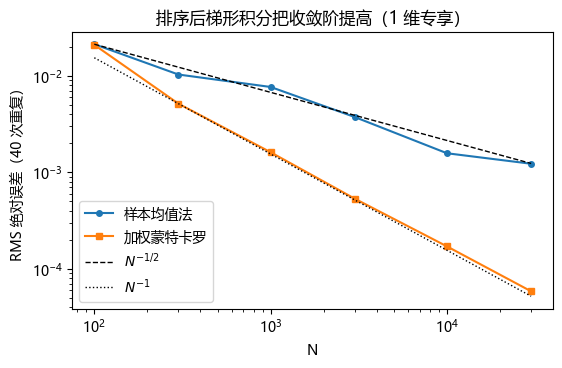

N=   100  样本均值 RMS 2.143e-02  加权 RMS 2.113e-02
N=   300  样本均值 RMS 1.038e-02  加权 RMS 5.168e-03
N=  1000  样本均值 RMS 7.708e-03  加权 RMS 1.618e-03
N=  3000  样本均值 RMS 3.755e-03  加权 RMS 5.325e-04
N= 10000  样本均值 RMS 1.579e-03  加权 RMS 1.702e-04
N= 30000  样本均值 RMS 1.229e-03  加权 RMS 5.812e-05


In [12]:
g = lambda x: np.exp(-x*x)
exact = 0.7468241328124271
Ns = np.array([100, 300, 1000, 3000, 10000, 30000])
R = 40
err_sm, err_w = [], []
for n in Ns:
    e1, e2 = [], []
    for _ in range(R):
        x = rng.random(n)
        e1.append(g(x).mean() - exact)
        xs = np.sort(x); gs = g(xs)
        w = np.empty(n)
        w[0] = (xs[1]-xs[0])/2; w[-1] = (xs[-1]-xs[-2])/2
        w[1:-1] = (xs[2:]-xs[:-2])/2
        e2.append((gs*w).sum() - exact)
    err_sm.append(np.sqrt(np.mean(np.square(e1))))   # RMS 误差，压制单次噪声
    err_w.append(np.sqrt(np.mean(np.square(e2))))
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.loglog(Ns, err_sm, "o-", ms=4, label="样本均值法")
ax.loglog(Ns, err_w, "s-", ms=4, label="加权蒙特卡罗")
ax.loglog(Ns, err_sm[0]*np.sqrt(Ns[0]/Ns), "k--", lw=1, label=r"$N^{-1/2}$")
ax.loglog(Ns, err_w[1]*(Ns[1]/Ns), "k:", lw=1, label=r"$N^{-1}$")
ax.set_xlabel("N"); ax.set_ylabel("RMS 绝对误差（40 次重复）"); ax.legend()
ax.set_title("排序后梯形积分把收敛阶提高（1 维专享）")
save(fig, "out-9-4.png"); plt.show()
for n, e1, e2 in zip(Ns, err_sm, err_w):
    print(f"N={n:6d}  样本均值 RMS {e1:.3e}  加权 RMS {e2:.3e}")